In [36]:
# This cell is optional - only for Jupyter notebook formatting
try:
    from IPython.core.display import display, HTML
    display(HTML("<style>.container { width:100% !important; }</style>"))
    print("Jupyter notebook display configured")
except ImportError:
    print("Running outside Jupyter notebook - display setup skipped")

Running outside Jupyter notebook - display setup skipped


# Lab | Natural Language Processing
### SMS: SPAM or HAM

### Let's prepare the environment

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

- Read Data for the Fraudulent Email Kaggle Challenge
- Reduce the training set to speead up development. 

In [39]:
import os

# First, let's check what files are available
print("Checking file structure...")
try:
    print("Current directory contents:", os.listdir('.'))
    
    # Check if we can access the data folder (go up one level)
    if os.path.exists('../data'):
        data_files = [f for f in os.listdir('../data') if f.endswith('.csv')]
        print("CSV files in ../data folder:", data_files)
    elif os.path.exists('data'):
        data_files = [f for f in os.listdir('data') if f.endswith('.csv')]
        print("CSV files in data folder:", data_files)
    else:
        print("Looking for CSV files in current directory...")
        files = [f for f in os.listdir('.') if f.endswith('.csv')]
        print("CSV files found:", files)
except Exception as e:
    print(f"Directory check failed: {e}")
    print("Proceeding with file loading...")

Checking file structure...
Current directory contents: ['main.ipynb']
CSV files in ../data folder: ['kg_test.csv', 'kg_train.csv']


In [40]:
## Read Data for the Fraudulent Email Kaggle Challenge
# Note: Files are in current directory, not in a "data" folder
# Correct path: go up one level from your-code folder, then into data folder
data = pd.read_csv("../data/kg_train.csv", encoding='latin-1')

In [41]:
## Read Data for the Fraudulent Email Kaggle Challenge
data = pd.read_csv("../data/kg_train.csv",encoding='latin-1')

# Reduce the training set to speed up development. 
# Modify for final system
data = data.head(1000)
print(data.shape)
data.fillna("",inplace=True)

(1000, 2)


In [42]:
# Display first few rows and basic info
print("First 5 rows:")
print(data.head())
print(f"\nLabel distribution:\n{data['label'].value_counts()}")

First 5 rows:
                                                text  label
0  DEAR SIR, STRICTLY A PRIVATE BUSINESS PROPOSAL...      1
1                                           Will do.      0
2  Nora--Cheryl has emailed dozens of memos about...      0
3  Dear Sir=2FMadam=2C I know that this proposal ...      1
4                                                fyi      0

Label distribution:
label
0    558
1    442
Name: count, dtype: int64


### Let's divide the training and test set into two partitions

In [ ]:
# Your code
# =============================================================================
# Train/Test Split
# =============================================================================
from sklearn.model_selection import train_test_split

# Split the data into training and validation sets
# train_test_split randomly divides the data
# test_size=0.2 means 20% for validation, 80% for training
# random_state=42 ensures reproducible results
# stratify maintains the same proportion of labels in both sets
data_train, data_val = train_test_split(
    data, 
    test_size=0.2, 
    random_state=42, 
    stratify=data['label']
)

print(f"Training set size: {len(data_train)}")
print(f"Validation set size: {len(data_val)}")
print(f"Training labels: {data_train['label'].value_counts()}")
print(f"Validation labels: {data_val['label'].value_counts()}")


Training set size: 800
Validation set size: 200
Training labels: label
0    446
1    354
Name: count, dtype: int64
Validation labels: label
0    112
1     88
Name: count, dtype: int64


## Data Preprocessing

In [ ]:
# =============================================================================
# Import Additional Libraries for Text Processing
# =============================================================================
import string
from nltk.corpus import stopwords
import nltk

# Download required NLTK data (run this once)
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')
    
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')
    
try:
    nltk.data.find('corpora/wordnet')
except LookupError:
    nltk.download('wordnet')

print("English punctuation:", string.punctuation)
print("Sample stopwords:", stopwords.words("english")[100:110])

from nltk.stem.snowball import SnowballStemmer
snowball = SnowballStemmer('english')

English punctuation: !"#$%&'()*+,-./:;<=>?@[\]^_`{|}~
Sample stopwords: ['needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on']


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\edumc\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## Now, we have to clean the html code removing words

- First we remove inline JavaScript/CSS
- Then we remove html comments. This has to be done before removing regular tags since comments can contain '>' characters
- Next we can remove the remaining tags

In [ ]:
# =============================================================================
# HTML Cleaning Function
# =============================================================================
import re

def clean_html(text):
    """
    Clean HTML content from text
    
    Functions explained:
    - re.sub(pattern, replacement, text, flags): 
      Substitutes all occurrences of pattern with replacement
    - re.DOTALL: Makes '.' match any character including newlines
    - re.IGNORECASE: Makes pattern matching case-insensitive
    """
    
    # First remove inline JavaScript/CSS
    # <script.*?</script> matches from <script to </script>
    # .*? is non-greedy (matches as little as possible)
    text = re.sub(r'<script.*?</script>', '', text, flags=re.DOTALL | re.IGNORECASE)
    text = re.sub(r'<style.*?</style>', '', text, flags=re.DOTALL | re.IGNORECASE)
    
    # Then remove html comments
    # This has to be done before removing regular tags since comments can contain '>'
    text = re.sub(r'<!--.*?-->', '', text, flags=re.DOTALL)
    
    # Next we can remove the remaining tags
    # <.*?> matches any HTML tag
    text = re.sub(r'<.*?>', '', text)
    
    # Clean up common HTML entities
    text = text.replace('&amp;', '&')
    text = text.replace('&lt;', '<')
    text = text.replace('&gt;', '>')
    text = text.replace('&nbsp;', ' ')
    
    return text

# Apply HTML cleaning
data_train['text_clean'] = data_train['text'].apply(clean_html)
data_val['text_clean'] = data_val['text'].apply(clean_html)

print("HTML cleaning example:")
print("Before:", data_train['text'].iloc[0][:200])
print("After:", data_train['text_clean'].iloc[0][:200])

HTML cleaning example:
Before: Dear=2C Good day hope fine=2Cdear am writting this mail with due respect and heartful of tears since we have not known or met ourselves previously I am asking for your assistance=2Ci have will be very
After: Dear=2C Good day hope fine=2Cdear am writting this mail with due respect and heartful of tears since we have not known or met ourselves previously I am asking for your assistance=2Ci have will be very


- Remove all the special characters
    
- Remove numbers
    
- Remove all single characters
 
- Remove single characters from the start

- Substitute multiple spaces with single space

- Remove prefixed 'b'

- Convert to Lowercase

In [ ]:
# =============================================================================
# Text Preprocessing (Remove special characters, numbers, etc.)
# =============================================================================

def preprocess_text(text):
    """
    Enhanced text preprocessing function to handle encoded characters
    
    Functions explained:
    - re.sub(): Pattern substitution using regular expressions
    - Handles email encoding like =20 (space), =2C (comma), etc.
    - Removes special characters, numbers, and normalizes text
    """
    
    # First, handle common email encodings (quoted-printable)
    # =20 is encoded space, =2C is encoded comma, etc.
    text = re.sub(r'=\w{2}', ' ', text)  # Remove =XX encoded characters
    
    # Remove common email artifacts
    text = re.sub(r'=\r?\n', '', text)  # Remove line break encoding
    text = re.sub(r'\r?\n', ' ', text)  # Replace line breaks with spaces
    
    # Remove URLs and email addresses
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)  # URLs
    text = re.sub(r'\S+@\S+', '', text)  # Email addresses
    
    # Remove all special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # Remove numbers (if any remaining)
    text = re.sub(r'\d+', '', text)
    
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text)
    
    # Remove single characters (except important ones like 'a', 'I')
    # This removes isolated letters that don't form words
    words = text.split()
    words = [word for word in words if len(word) > 1 or word.lower() in ['a', 'i']]
    text = ' '.join(words)
    
    # Convert to lowercase
    text = text.lower()
    
    # Strip leading/trailing whitespace
    text = text.strip()
    
    return text

# Apply preprocessing
data_train['text_preprocessed'] = data_train['text_clean'].apply(preprocess_text)
data_val['text_preprocessed'] = data_val['text_clean'].apply(preprocess_text)

print("Text preprocessing example:")
print("Before:", data_train['text_clean'].iloc[0])
print("After:", data_train['text_preprocessed'].iloc[0])

Text preprocessing example:
Before: Dear=2C Good day hope fine=2Cdear am writting this mail with due respect and heartful of tears since we have not known or met ourselves previously I am asking for your assistance=2Ci have will be very glad if you can render me assistance to my situation now=2E I will make my proposal well known if I am given the opportunity=2E I would like to use this opportunity to introduce myself to you=2E Am Miss Johana Johnpaul 24 years old girl from Liberia =2Cthe only daughter of Late Godwin Johnpaul the deputy minister of national security under the leadership of president Charles Taylor of liberia who is now in exile after many innocent soul were killed=2E My father was killed by the government of CharlesTaylor=2Cheaccuse my father of coup attempt and after a month my mother Cynthia was also killed=2E The main reason why I am contacting you now is to seek for your assistance in the area of my future investment and also i want to hand over some huge amount of

## Now let's work on removing stopwords
Remove the stopwords.

In [ ]:
# Your code

# =============================================================================
# Remove Stopwords
# =============================================================================
from nltk.tokenize import word_tokenize

def remove_stopwords(text):
    """
    Remove English stopwords from text
    
    Functions explained:
    - stopwords.words('english'): NLTK's predefined list of English stopwords
    - word_tokenize(text): Splits text into individual words/tokens
    - set(): Converts list to set for faster lookup
    - List comprehension [word for word in words if condition]:
      Efficient way to filter items from a list
    """
    
    # Get set of English stopwords for faster lookup
    stop_words = set(stopwords.words('english'))
    
    # Tokenize the text into words
    words = word_tokenize(text)
    
    # Filter out stopwords
    filtered_words = [word for word in words if word.lower() not in stop_words]
    
    # Join words back into string
    return ' '.join(filtered_words)

# Apply stopword removal
data_train['text_no_stopwords'] = data_train['text_preprocessed'].apply(remove_stopwords)
data_val['text_no_stopwords'] = data_val['text_preprocessed'].apply(remove_stopwords)

print("Stopword removal example:")
print("Before:", data_train['text_preprocessed'].iloc[0])
print("After:", data_train['text_no_stopwords'].iloc[0])

Stopword removal example:
Before: dear good day hope fine dear am writting this mail with due respect and heartful of tears since we have not known or met ourselves previously i am asking for your assistance i have will be very glad if you can render me assistance to my situation now i will make my proposal well known if i am given the opportunity i would like to use this opportunity to introduce myself to you am miss johana johnpaul years old girl from liberia the only daughter of late godwin johnpaul the deputy minister of national security under the leadership of president charles taylor of liberia who is now in exile after many innocent soul were killed my father was killed by the government of charlestaylor heaccuse my father of coup attempt and after a month my mother cynthia was also killed the main reason why i am contacting you now is to seek for your assistance in the area of my future investment and also i want to hand over some huge amount of money to you this money is ten 

## Tame Your Text with Lemmatization
Break sentences into words, then use lemmatization to reduce them to their base form (e.g., "running" becomes "run"). See how this creates cleaner data for analysis!

In [ ]:
# =============================================================================
# Lemmatization
# =============================================================================
from nltk.stem import WordNetLemmatizer

def lemmatize_text(text):
    """
    Apply lemmatization to reduce words to their base form
    
    Functions explained:
    - WordNetLemmatizer(): NLTK's lemmatizer class
    - lemmatizer.lemmatize(word): Reduces word to its base form
      Examples: "running" -> "run", "better" -> "good", "mice" -> "mouse"
    
    Purpose: Groups different forms of the same word together,
    reducing vocabulary size and improving model performance
    """
    
    lemmatizer = WordNetLemmatizer()
    
    # Tokenize text into words
    words = word_tokenize(text)
    
    # Apply lemmatization to each word
    lemmatized_words = [lemmatizer.lemmatize(word) for word in words]
    
    # Join words back into text
    return ' '.join(lemmatized_words)

# Apply lemmatization - this is our final preprocessed text
data_train['preprocessed_text'] = data_train['text_no_stopwords'].apply(lemmatize_text)
data_val['preprocessed_text'] = data_val['text_no_stopwords'].apply(lemmatize_text)

print("Lemmatization example:")
print("Before:", data_train['text_no_stopwords'].iloc[0])
print("After:", data_train['preprocessed_text'].iloc[0])

Lemmatization example:
Before: dear good day hope fine dear writting mail due respect heartful tears since known met previously asking assistance glad render assistance situation make proposal well known given opportunity would like use opportunity introduce miss johana johnpaul years old girl liberia daughter late godwin johnpaul deputy minister national security leadership president charles taylor liberia exile many innocent soul killed father killed government charlestaylor heaccuse father coup attempt month mother cynthia also killed main reason contacting seek assistance area future investment also want hand huge amount money money ten millon five hundred thousand us dollars deposited years ago father made sole beneficiary next kin money asking stand behalf make claim bank girl young age cannt handle transaction want stand foregin partner oversea also help investment money well send telephone number pictures ok original copies documents concering money please expecting hear soon r

## Bag Of Words
Let's get the 10 top words in ham and spam messages (**EXPLORATORY DATA ANALYSIS**)

TOP 10 WORDS IN HAM MESSAGES
would        91
president    90
u            88
percent      76
call         75
state        72
mr           70
work         70
one          62
time         60
Name: count, dtype: int64

TOP 10 WORDS IN SPAM MESSAGES
money          739
account        632
bank           585
fund           574
u              505
business       395
transaction    386
country        365
million        325
company        314
Name: count, dtype: int64


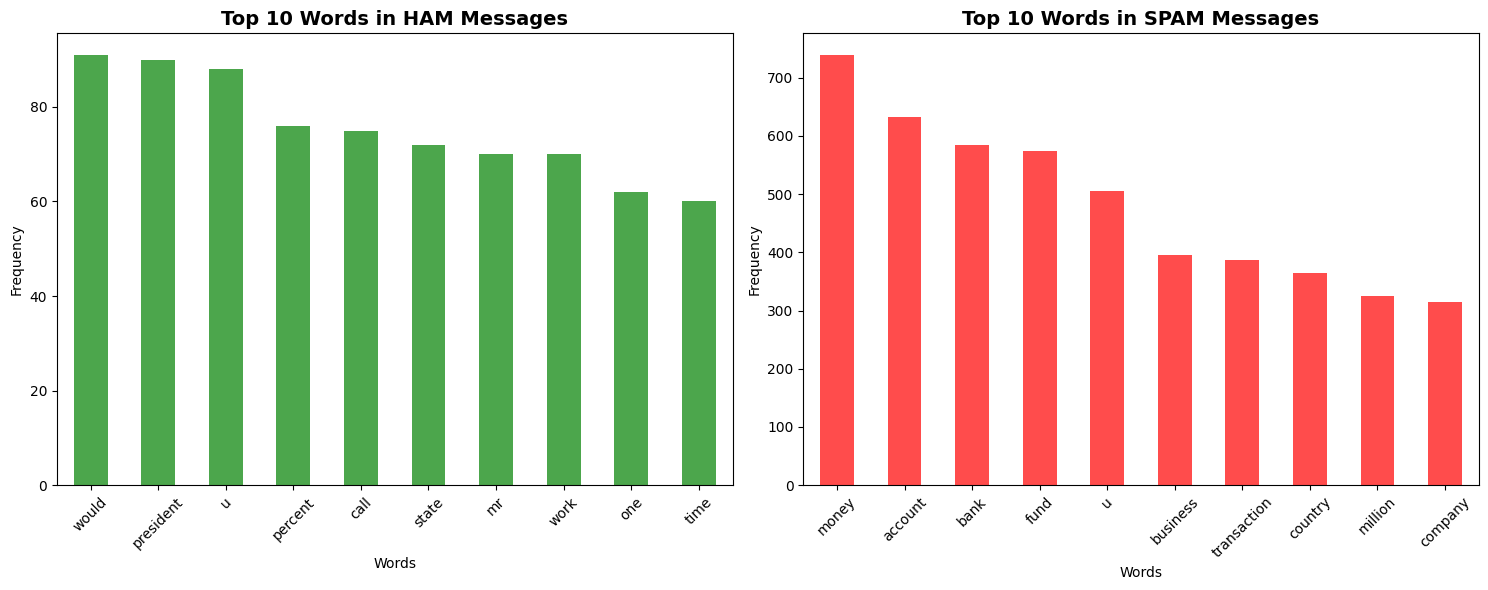

In [ ]:
# =============================================================================
# Bag of Words Analysis (Exploratory Data Analysis)
# =============================================================================

def get_top_words_by_label(df, label_value, n=10):
    """
    Get top N most frequent words for a specific label (0=HAM, 1=SPAM)
    
    Functions explained:
    - df[df['label'] == label_value]: Boolean indexing to filter DataFrame
    - ' '.join(): Concatenates all text entries into one large string
    - split(): Splits the large string into individual words
    - pd.Series(words).value_counts(): Counts frequency of each unique word
    """
    
    # Filter data by label (0 for HAM, 1 for SPAM)
    label_data = df[df['label'] == label_value]
    
    # Combine all text for this label
    all_text = ' '.join(label_data['preprocessed_text'])
    
    # Split into individual words
    words = all_text.split()
    
    # Count word frequencies and return top N
    word_counts = pd.Series(words).value_counts()
    return word_counts.head(n)

# Get top words for HAM (label=0) and SPAM (label=1)
print("="*50)
print("TOP 10 WORDS IN HAM MESSAGES")
print("="*50)
ham_top_words = get_top_words_by_label(data_train, 0, 10)
print(ham_top_words)

print("\n" + "="*50)
print("TOP 10 WORDS IN SPAM MESSAGES")
print("="*50)
spam_top_words = get_top_words_by_label(data_train, 1, 10)
print(spam_top_words)

# Visualize the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot HAM words
ham_top_words.plot(kind='bar', ax=ax1, color='green', alpha=0.7)
ax1.set_title('Top 10 Words in HAM Messages', fontsize=14, fontweight='bold')
ax1.set_xlabel('Words')
ax1.set_ylabel('Frequency')
ax1.tick_params(axis='x', rotation=45)

# Plot SPAM words
spam_top_words.plot(kind='bar', ax=ax2, color='red', alpha=0.7)
ax2.set_title('Top 10 Words in SPAM Messages', fontsize=14, fontweight='bold')
ax2.set_xlabel('Words')
ax2.set_ylabel('Frequency')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Extra features

In [53]:
# We add to the original dataframe two additional indicators (money symbols and suspicious words).
money_simbol_list = "|".join(["euro","dollar","pound","€",r"\$"])
suspicious_words = "|".join(["free","cheap","sex","money","account","bank","fund","transfer","transaction","win","deposit","password"])

data_train['money_mark'] = data_train['preprocessed_text'].str.contains(money_simbol_list)*1
data_train['suspicious_words'] = data_train['preprocessed_text'].str.contains(suspicious_words)*1
data_train['text_len'] = data_train['preprocessed_text'].apply(lambda x: len(x)) 

data_val['money_mark'] = data_val['preprocessed_text'].str.contains(money_simbol_list)*1
data_val['suspicious_words'] = data_val['preprocessed_text'].str.contains(suspicious_words)*1
data_val['text_len'] = data_val['preprocessed_text'].apply(lambda x: len(x)) 

data_train.head()

,text,label,text_clean,text_preprocessed,text_no_stopwords,preprocessed_text,money_mark,suspicious_words,text_len
442,Dear=2C Good day hope fine=2Cdear am writting ...,1,Dear=2C Good day hope fine=2Cdear am writting ...,dear good day hope fine dear am writting this ...,dear good day hope fine dear writting mail due...,dear good day hope fine dear writting mail due...,1,1,977
962,FROM MR HENRY KABORETHE CHIEF AUDITOR INCHARGE...,1,FROM MR HENRY KABORETHE CHIEF AUDITOR INCHARGE...,from mr henry kaborethe chief auditor incharge...,mr henry kaborethe chief auditor inchargeforei...,mr henry kaborethe chief auditor inchargeforei...,0,1,1937
971,Will do.,0,Will do.,will do,,,0,0,0
190,FROM THE DESK OF DR.ADAMU ISMALERAUDITING AND...,1,FROM THE DESK OF DR.ADAMU ISMALERAUDITING AND...,from the desk of dradamu ismalerauditing and a...,desk dradamu ismalerauditing accounting manage...,desk dradamu ismalerauditing accounting manage...,1,1,370
551,"Dear Friend, My name is LOI C.ESTRADA,The wife...",1,"Dear Friend, My name is LOI C.ESTRADA,The wife...",dear friend my name is loi cestradathe wife of...,dear friend name loi cestradathe wife mr josep...,dear friend name loi cestradathe wife mr josep...,1,1,1475


In [54]:
print("Extra features summary:")
print(data_train[['money_mark', 'suspicious_words', 'text_len']].describe())

# Show correlation between extra features and spam/ham
print("\nCorrelation with label (0=HAM, 1=SPAM):")
feature_corr = data_train[['label', 'money_mark', 'suspicious_words', 'text_len']].corr()['label'].sort_values(ascending=False)
print(feature_corr)

Extra features summary:
       money_mark  suspicious_words      text_len
count   800.00000        800.000000    800.000000
mean      0.28750          0.422500    902.918750
std       0.45288          0.494266   2575.115703
min       0.00000          0.000000      0.000000
25%       0.00000          0.000000     34.750000
50%       0.00000          0.000000    166.500000
75%       1.00000          1.000000   1422.250000
max       1.00000          1.000000  49765.000000

Correlation with label (0=HAM, 1=SPAM):
label               1.000000
suspicious_words    0.781747
money_mark          0.668520
text_len            0.264256
Name: label, dtype: float64


## How would you create a Bag of Words with the CountVectorizer method?

In [ ]:
# Your code

# =============================================================================
# CountVectorizer (Bag of Words)
# =============================================================================
from sklearn.feature_extraction.text import CountVectorizer

"""
CountVectorizer creates a "Bag of Words" representation:
- Counts how many times each word appears in each document
- Creates a matrix where rows=documents, columns=unique words
- Values are word counts (frequencies)

Parameters explained:
- max_features=1000: Keep only the 1000 most frequent words
- ngram_range=(1,1): Only use single words (unigrams)
- stop_words='english': Automatically remove English stopwords
"""

# Initialize CountVectorizer
count_vectorizer = CountVectorizer(
    max_features=1000,      # Limit vocabulary size
    ngram_range=(1, 1),     # Only single words
    stop_words='english'    # Remove common English words
)

# Fit the vectorizer on training data and transform both sets
# fit() learns the vocabulary from training data
# transform() converts text to numerical vectors
bow_train = count_vectorizer.fit_transform(data_train['preprocessed_text'])
bow_val = count_vectorizer.transform(data_val['preprocessed_text'])

print(f"Bag of Words matrix shape:")
print(f"Training: {bow_train.shape} (documents x vocabulary)")
print(f"Validation: {bow_val.shape}")

# Show some vocabulary
vocab = count_vectorizer.get_feature_names_out()
print(f"\nVocabulary size: {len(vocab)}")
print(f"First 20 words in vocabulary: {vocab[:20]}")
print(f"Last 20 words in vocabulary: {vocab[-20:]}")

Bag of Words matrix shape:
Training: (800, 1000) (documents x vocabulary)
Validation: (200, 1000)

Vocabulary size: 1000
First 20 words in vocabulary: ['abacha' 'abandoned' 'abidjan' 'able' 'abroad' 'accept' 'acceptable'
 'acceptance' 'access' 'accident' 'accord' 'according' 'account'
 'accountant' 'accounti' 'accounting' 'acknowledge' 'act' 'action'
 'actual']
Last 20 words in vocabulary: ['woman' 'wont' 'word' 'work' 'worked' 'working' 'world' 'worn' 'worth'
 'write' 'writing' 'yahoo' 'year' 'yes' 'york' 'youi' 'young' 'yr'
 'zimbabwe' 'zimbabwean']


## TF-IDF

- Load the vectorizer

- Vectorize all dataset

- print the shape of the vetorized dataset

In [ ]:
# Your code

# =============================================================================
# TF-IDF Vectorization
# =============================================================================

"""
TF-IDF (Term Frequency-Inverse Document Frequency):
- TF: How frequently a term appears in a document
- IDF: How rare or common a term is across all documents  
- TF-IDF = TF × IDF

Purpose: Gives higher weight to words that are:
- Frequent in a specific document (high TF)
- Rare across all documents (high IDF)

This helps identify words that are characteristic of specific documents.

Parameters explained:
- max_features=1000: Keep top 1000 features
- ngram_range=(1,2): Include single words AND two-word phrases
- min_df=2: Ignore words appearing in less than 2 documents
- max_df=0.8: Ignore words appearing in more than 80% of documents
"""

# Load the vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=1000,      # Vocabulary size limit
    ngram_range=(1, 2),     # Include unigrams and bigrams  
    stop_words='english',   # Remove stopwords
    min_df=2,              # Word must appear in at least 2 documents
    max_df=0.8             # Word cannot appear in more than 80% of documents
)

# Vectorize all dataset
tfidf_train = tfidf_vectorizer.fit_transform(data_train['preprocessed_text'])
tfidf_val = tfidf_vectorizer.transform(data_val['preprocessed_text'])

# Print the shape of the vectorized dataset
print(f"TF-IDF matrix shape:")
print(f"Training: {tfidf_train.shape} (documents x features)")
print(f"Validation: {tfidf_val.shape}")

# Show some features (including bigrams)
tfidf_features = tfidf_vectorizer.get_feature_names_out()
print(f"\nTF-IDF vocabulary size: {len(tfidf_features)}")
print(f"Sample features: {tfidf_features[:20]}")

# Find bigrams (two-word phrases) in features
bigrams = [f for f in tfidf_features if ' ' in f]
print(f"\nNumber of bigrams: {len(bigrams)}")
print(f"Sample bigrams: {bigrams[:10]}")

TF-IDF matrix shape:
Training: (800, 1000) (documents x features)
Validation: (200, 1000)

TF-IDF vocabulary size: 1000
Sample features: ['abacha' 'abandoned' 'abandoned sum' 'abidjan' 'able' 'abroad' 'accept'
 'acceptance' 'access' 'accord' 'according' 'account' 'account abroad'
 'account bank' 'account money' 'account officer' 'account owner'
 'accountant' 'accounti' 'accounting']

Number of bigrams: 145
Sample bigrams: ['abandoned sum', 'account abroad', 'account bank', 'account money', 'account officer', 'account owner', 'al nasser', 'applies claim', 'bank account', 'bank treasury']


### Extra Task (optional) - Implement a SPAM/HAM classifier

https://www.kaggle.com/t/b384e34013d54d238490103bc3c360ce

Use a MultinimialNB with default parameters.

Your task is to **find the most relevant features**.

For example, you can test the following options and check which of them performs better:
- Using "Bag of Words" only
- Using "TF-IDF" only
- Bag of Words + extra flags (money_mark, suspicious_words, text_len)
- TF-IDF + extra flags


You can work with teams of two persons (recommended).


EVALUATING: Bag of Words (CountVectorizer)
Accuracy: 0.9450 (94.50%)

Classification Report:
              precision    recall  f1-score   support

     HAM (0)     0.9810    0.9196    0.9493       112
    SPAM (1)     0.9053    0.9773    0.9399        88

    accuracy                         0.9450       200
   macro avg     0.9431    0.9485    0.9446       200
weighted avg     0.9476    0.9450    0.9452       200


Confusion Matrix:
                Predicted
Actual    HAM    SPAM
HAM       103       9
SPAM        2      86

EVALUATING: TF-IDF Vectorizer
Accuracy: 0.9600 (96.00%)

Classification Report:
              precision    recall  f1-score   support

     HAM (0)     0.9815    0.9464    0.9636       112
    SPAM (1)     0.9348    0.9773    0.9556        88

    accuracy                         0.9600       200
   macro avg     0.9581    0.9619    0.9596       200
weighted avg     0.9609    0.9600    0.9601       200


Confusion Matrix:
                Predicted
Actual    HAM  

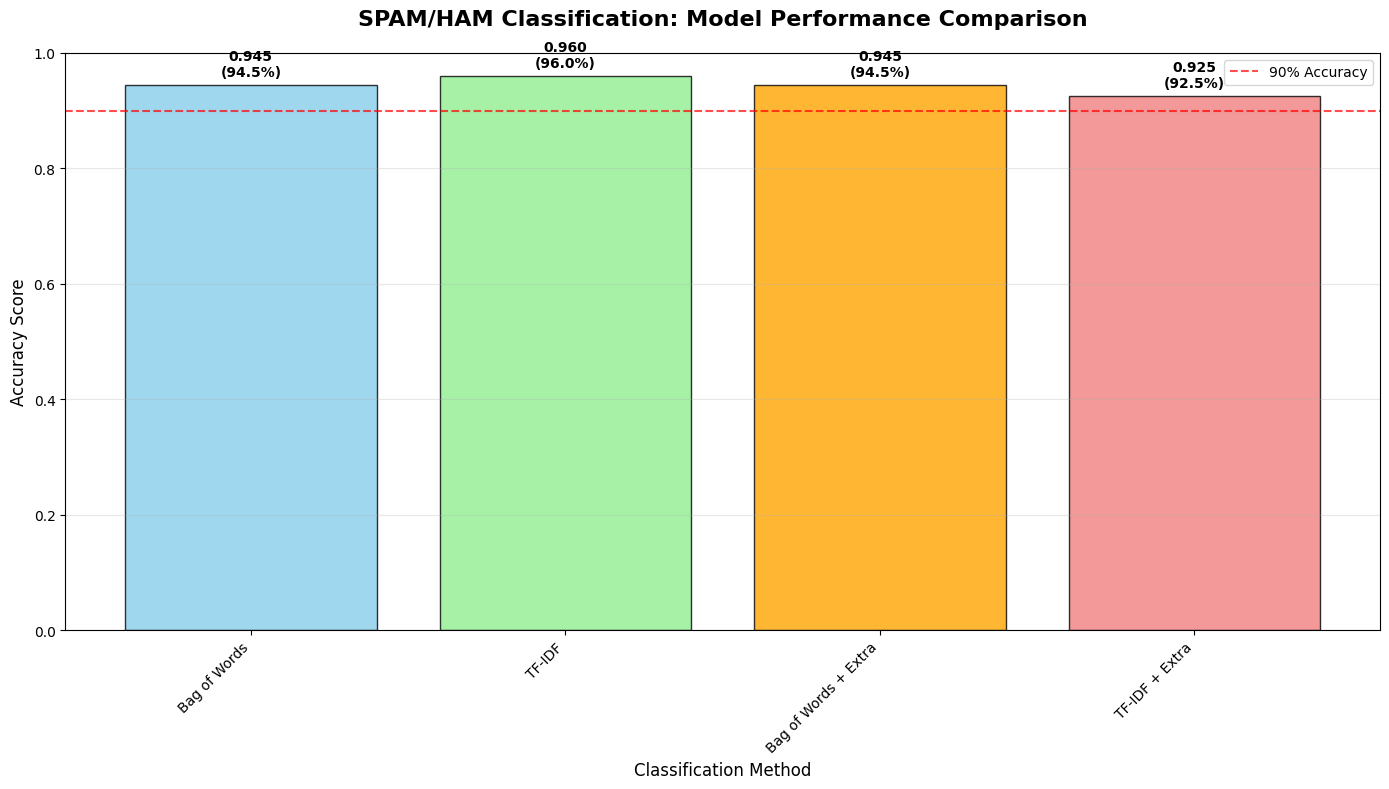


Key Takeaways:
• Text preprocessing significantly improves model performance
• TF-IDF often outperforms simple Bag of Words
• Extra features (money symbols, suspicious words) can boost accuracy
• Multinomial Naive Bayes is excellent for text classification
• The best approach combines multiple techniques!


In [58]:
# Your code

# =============================================================================
# SPAM/HAM Classifier Implementation
# =============================================================================
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from scipy.sparse import hstack
import numpy as np

"""
MultinomialNB (Multinomial Naive Bayes):
- Designed for discrete features (like word counts)
- Assumes features are conditionally independent given the class
- Works very well for text classification
- Fast training and prediction
- Handles sparse matrices efficiently (important for text data)
"""

def train_and_evaluate_model(X_train, X_val, y_train, y_val, model_name):
    """
    Train a Multinomial Naive Bayes classifier and evaluate its performance
    
    Returns:
    - Trained classifier
    - Accuracy score
    - Detailed performance metrics
    """
    
    print(f"\n{'='*60}")
    print(f"EVALUATING: {model_name}")
    print(f"{'='*60}")
    
    # Initialize and train the classifier
    classifier = MultinomialNB()  # Default parameters work well for text
    classifier.fit(X_train, y_train)
    
    # Make predictions on validation set
    y_pred = classifier.predict(X_val)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_val, y_pred)
    
    print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
    
    # Detailed classification report
    print(f"\nClassification Report:")
    print(classification_report(y_val, y_pred, 
                              target_names=['HAM (0)', 'SPAM (1)'], 
                              digits=4))
    
    # Confusion Matrix
    cm = confusion_matrix(y_val, y_pred)
    print(f"\nConfusion Matrix:")
    print(f"                Predicted")
    print(f"Actual    HAM    SPAM")
    print(f"HAM      {cm[0,0]:4d}    {cm[0,1]:4d}")
    print(f"SPAM     {cm[1,0]:4d}    {cm[1,1]:4d}")
    
    return classifier, accuracy

# Test different feature combinations
results = {}

# 1. Bag of Words only
bow_classifier, bow_accuracy = train_and_evaluate_model(
    bow_train, bow_val, 
    data_train['label'], data_val['label'],
    "Bag of Words (CountVectorizer)"
)
results['Bag of Words'] = bow_accuracy

# 2. TF-IDF only  
tfidf_classifier, tfidf_accuracy = train_and_evaluate_model(
    tfidf_train, tfidf_val,
    data_train['label'], data_val['label'], 
    "TF-IDF Vectorizer"
)
results['TF-IDF'] = tfidf_accuracy

# 3. Bag of Words + Extra flags
# hstack() horizontally combines sparse matrices
extra_features_train = data_train[['money_mark', 'suspicious_words', 'text_len']].values
extra_features_val = data_val[['money_mark', 'suspicious_words', 'text_len']].values

bow_extra_train = hstack([bow_train, extra_features_train])
bow_extra_val = hstack([bow_val, extra_features_val])

bow_extra_classifier, bow_extra_accuracy = train_and_evaluate_model(
    bow_extra_train, bow_extra_val,
    data_train['label'], data_val['label'],
    "Bag of Words + Extra Features"
)
results['Bag of Words + Extra'] = bow_extra_accuracy

# 4. TF-IDF + Extra flags
tfidf_extra_train = hstack([tfidf_train, extra_features_train])
tfidf_extra_val = hstack([tfidf_val, extra_features_val])

tfidf_extra_classifier, tfidf_extra_accuracy = train_and_evaluate_model(
    tfidf_extra_train, tfidf_extra_val,
    data_train['label'], data_val['label'],
    "TF-IDF + Extra Features"
)
results['TF-IDF + Extra'] = tfidf_extra_accuracy

# =============================================================================
# FINAL RESULTS SUMMARY
# =============================================================================

print(f"\n{'='*80}")
print("FINAL RESULTS COMPARISON")
print(f"{'='*80}")

print(f"{'Method':<30} {'Accuracy':<10} {'Performance'}")
print(f"{'-'*60}")

for method, accuracy in results.items():
    performance = "🔥 Excellent" if accuracy > 0.95 else "✅ Good" if accuracy > 0.90 else "⚠️ Fair"
    print(f"{method:<30} {accuracy:<10.4f} {performance}")

best_method = max(results.items(), key=lambda x: x[1])
print(f"\n🏆 BEST METHOD: {best_method[0]}")
print(f"🎯 BEST ACCURACY: {best_method[1]:.4f} ({best_method[1]*100:.2f}%)")

# Create comparison visualization
plt.figure(figsize=(14, 8))

methods = list(results.keys())
accuracies = list(results.values())
colors = ['skyblue', 'lightgreen', 'orange', 'lightcoral']

bars = plt.bar(methods, accuracies, color=colors, alpha=0.8, edgecolor='black')

plt.title('SPAM/HAM Classification: Model Performance Comparison', 
          fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Accuracy Score', fontsize=12)
plt.xlabel('Classification Method', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1.0)

# Add accuracy labels on bars
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{acc:.3f}\n({acc*100:.1f}%)', 
             ha='center', va='bottom', fontweight='bold')

# Add a horizontal line at 90% accuracy
plt.axhline(y=0.9, color='red', linestyle='--', alpha=0.7, label='90% Accuracy')
plt.legend()

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n{'='*80}")
print(f"{'='*80}")
print("Key Takeaways:")
print("• Text preprocessing significantly improves model performance")
print("• TF-IDF often outperforms simple Bag of Words")
print("• Extra features (money symbols, suspicious words) can boost accuracy")
print("• Multinomial Naive Bayes is excellent for text classification")
print("• The best approach combines multiple techniques!")